# Jaipur Built-up Surface Expansion (2005–2020)
**Raushan:** Raushan Vivek  |  **Roll no.:** CS25M115  
**Assignment:** Jaipur — *Map the spatial expansion of built-up surface relative to the 2005 footprint*  
**Datasets:** GHSL Built-up Surface + Jaipur Urban Local Body boundary  
**Workflow:** Google Earth Engine + geemap, following the time-series/time-lapse workflow from Lectures 24–27 and 28–30.


In [1]:
import ee
import geemap
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ID = "bubbly-poetry-510709-n9" 
ee.Authenticate()
ee.Initialize(project=PROJECT_ID)




*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [2]:
ULB_FILE = "SBM_ULBs.geojsonl"  


## 2. Load and identify Jaipur's Urban Local Body boundary
The release contains ULB boundaries, so use `SBM_ULBs.geojsonl.7z` rather than ward/locality boundaries. First inspect all records matching Jaipur. Select the row representing the intended Jaipur municipal/ULB boundary; do not accidentally choose a ward or Jaipur district boundary.

In [3]:
ulbs = gpd.read_file(ULB_FILE, driver="GeoJSONSeq")
# Display all records matching Jaipur
attribute_cols = [c for c in ulbs.columns if c != "geometry"]

match_mask = ulbs[attribute_cols].astype(str).apply(
    lambda col: col.str.contains("Jaipur", case=False, na=False)
).any(axis=1)

jaipur_candidates = ulbs.loc[match_mask].copy()

print("Number of Jaipur candidates:", len(jaipur_candidates))
print("Candidate row indices:", jaipur_candidates.index.tolist())

display(jaipur_candidates.drop(columns="geometry", errors="ignore"))

Number of Jaipur candidates: 5
Candidate row indices: [2330, 2402, 2729, 2757, 2763]


,objectid,stnm,stcode,distnm,distcode,ulbnm,ulbcode,remark,st_area(shape),st_perimeter(shape)
2330,53466,,8,JAIPUR,110,JAIPUR,800522,Ok Approved,0.009864,0.874235
2402,59053,,8,,110,NAGAR NIGAM GREATEER JAIPUR,900600,,0.031165,1.609447
2729,79486,,8,JAIPUR,110,BAGRU,800521,,0.002804,0.315947
2757,81088,,8,JAIPUR,110,CHOMU,800516,Ok,0.001927,0.228587
2763,81487,,8,JAIPUR,110,BASSI,900711,,0.001871,0.322112


In [4]:
# Select the verified Jaipur ULB explicitly.
# This avoids accidentally including Bagru, Chomu, Bassi, or the larger Nagar Nigam Greater Jaipur record.
jaipur_gdf = ulbs[
    ulbs["ulbnm"].astype(str).str.strip().str.upper() == "JAIPUR"
].copy()

if jaipur_gdf.empty:
    raise ValueError("The exact ULB name JAIPUR was not found. Inspect ulbs['ulbnm'].unique().")

jaipur_gdf = jaipur_gdf[
    jaipur_gdf.geometry.notna() & ~jaipur_gdf.geometry.is_empty
].to_crs("EPSG:4326")

# Dissolve only the exact JAIPUR ULB record(s), then convert to Earth Engine.
jaipur_gdf = jaipur_gdf.dissolve()
jaipur = geemap.geopandas_to_ee(jaipur_gdf)

print("Selected ULB:", jaipur_gdf["ulbnm"].iloc[0] if "ulbnm" in jaipur_gdf.columns else "JAIPUR")
print("Jaipur boundary loaded successfully!")
print("Number of boundary features:", len(jaipur_gdf))
display(jaipur_gdf.drop(columns="geometry", errors="ignore"))


Selected ULB: JAIPUR
Jaipur boundary loaded successfully!
Number of boundary features: 1


,objectid,stnm,stcode,distnm,distcode,ulbnm,ulbcode,remark,st_area(shape),st_perimeter(shape)
0,53466,,8,JAIPUR,110,JAIPUR,800522,Ok Approved,0.009864,0.874235


## 3. Load GHSL built-up surface
Dataset: `JRC/GHSL/P2023A/GHS_BUILT_S`. The `built_surface` band reports square metres of built-up surface per 100 m grid cell. The selected epochs are 2005, 2010, 2015 and 2020.

### Applied filters
- **Spatial:** clip every epoch to the same Jaipur ULB geometry.
- **Temporal:** use exactly the four GHSL epochs required by the assignment: 2005, 2010, 2015 and 2020.
- **Quality:** no additional cloud/QA mask is applied because this GHSL built-surface product is not a Sentinel-5P/optical monthly image collection requiring cloud masking.
- **Consistency:** the same band, boundary, nominal scale (100 m), and visualization range are used across epochs.

**Interpretation:** the summed `built_surface` is mapped built-up surface, not the total land area of Jaipur. A 100 m cell can be only partly built-up.

In [5]:
EPOCHS = [2005, 2010, 2015, 2020]
GHSL_ID = "JRC/GHSL/P2023A/GHS_BUILT_S"

# Catalog assets are individual epoch images; use the documented epoch asset IDs.
built_images = {}
for year in EPOCHS:
    built_images[year] = (
        ee.Image(f"{GHSL_ID}/{year}")
        .select("built_surface")
        .clipToCollection(jaipur)
        .rename("built_surface")
        .set("year", year)
        .set("system:time_start", ee.Date.fromYMD(year, 1, 1).millis())
    )

# Verify that the expected band is present and images are accessible.
print("Epochs:", EPOCHS)
print("2005 band names:", ee.Image(f"{GHSL_ID}/2005").bandNames().getInfo())


Epochs: [2005, 2010, 2015, 2020]
2005 band names: ['built_surface', 'built_surface_nres']


## 4. Thematic maps — four GHSL epochs
All four epochs use the **same visualization scale (0–10,000 m² per 100 m cell)** so that visual differences represent data differences rather than changing display limits. The Jaipur ULB boundary is overlaid and a colour bar gives the units.


In [6]:
built_vis = {
    "min": 0,
    "max": 10000,
    "palette": ["ffffff", "fee8c8", "fdbb84", "e34a33", "7f0000"]
}

Map = geemap.Map()
Map.centerObject(jaipur, 10)
for year in EPOCHS:
    Map.addLayer(built_images[year], built_vis, f"Built-up surface {year}", shown=(year == 2020))
Map.addLayer(jaipur, {"color": "00ffff"}, "Jaipur ULB boundary")
Map.add_colorbar(built_vis, label="Built-up surface (m² per 100 m cell)")
Map.addLayerControl()
print("JAIPUR — GHSL BUILT-UP SURFACE, 2005–2020")
Map


JAIPUR — GHSL BUILT-UP SURFACE, 2005–2020


Map(center=[26.93056657210049, 75.83465531014457], controls=(WidgetControl(options=['position', 'transparent_b…

## 5. Interactive epoch slider
This follows the lecture's `ImageCollection` + `add_time_slider` pattern. Since GHSL provides five-year epochs, the slider moves through 2005, 2010, 2015 and 2020.

In [7]:
epoch_collection = ee.ImageCollection.fromImages(
    [built_images[y] for y in EPOCHS]
).sort("system:time_start")

Map_slider = geemap.Map()
Map_slider.centerObject(jaipur, 10)
Map_slider.add_time_slider(
    epoch_collection,
    built_vis,
    region=jaipur.geometry(),
    layer_name="GHSL built-up surface",
    labels=[str(y) for y in EPOCHS],
    time_interval=5,
    position="bottomright"
)
Map_slider.addLayer(jaipur, {"color": "00ffff"}, "Jaipur ULB boundary")
Map_slider.add_colorbar(built_vis, label="Built-up surface (m² per 100 m cell)")
Map_slider

# Save the interactive time-slider map as a standalone HTML file.
# The explicit file check prevents a silent failure.
from pathlib import Path

slider_html = Path("Jaipur_GHSL_TimeSlider_2005_2020.html")
try:
    Map_slider.to_html(outfile=str(slider_html))
except TypeError:
    Map_slider.to_html(str(slider_html))
except Exception as exc:
    # Some geemap versions expose save() instead of to_html().
    try:
        Map_slider.save(str(slider_html))
    except Exception as exc2:
        raise RuntimeError(
            "Could not save the interactive time-slider HTML. "
            f"to_html error: {exc}; save error: {exc2}"
        )

if not slider_html.exists() or slider_html.stat().st_size < 1000:
    raise RuntimeError(
        f"Time-slider HTML was not created correctly: {slider_html.resolve()}"
    )

print(f"✓ Interactive time-slider saved: {slider_html.resolve()}")
print(f"✓ File size: {slider_html.stat().st_size:,} bytes")


✓ Interactive time-slider saved: C:\Users\raush\Downloads\MTech\3rd Sem\Urban\Test_2\Test\Jaipur_GHSL_TimeSlider_2005_2020.html
✓ File size: 100,490 bytes


## 6. Create a labelled GIF
As in the lecture notebook, convert each image to RGB visual bands, use the same region and colour scale for every frame, and add year labels. The GIF has four frames, not sixteen annual frames.

In [8]:

def visualize_built(image):
    return image.visualize(**built_vis).copyProperties(
        image, ["system:time_start", "year"]
    )

gif_collection = epoch_collection.map(visualize_built)
gif_file = "Jaipur_GHSL_builtup_2005_2020.gif"
video_args = {
    "dimensions": 800,
    "region": jaipur.geometry(),
    "framesPerSecond": 1,
    "crs": "EPSG:3857",
    "bands": ["vis-red", "vis-green", "vis-blue"],
    "min": 0,
    "max": 255
}

geemap.download_ee_video(gif_collection, video_args, gif_file)

labelled_gif = "Jaipur_GHSL_builtup_2005_2020_labelled.gif"
geemap.add_text_to_gif(
    gif_file,
    labelled_gif,
    xy=("5%", "5%"),
    text_sequence=[str(y) for y in EPOCHS],
    font_size=28,
    font_color="white",
    add_progress_bar=True,
    progress_bar_color="white"
)
geemap.show_image(labelled_gif)



Generating URL...
Please wait ...
The GIF image has been saved to: C:\Users\raush\Downloads\MTech\3rd Sem\Urban\Test_2\Test\Jaipur_GHSL_builtup_2005_2020.gif


Output()

## 7. Spatial expansion relative to the 2005 footprint
We calculate two complementary products:

- **Net change (2020 − 2005):** positive values indicate an increase in mapped built-up surface; negative values indicate a decrease.
- **Positive expansion only:** negative differences are set to zero so that locations of increase can be identified clearly.

The expansion map therefore answers the assignment question spatially: *where did mapped built-up surface increase relative to the 2005 baseline?* It does not prove the exact construction date, building type, or cause of change.

In [9]:
built_2005 = built_images[2005]
built_2020 = built_images[2020]

net_change = built_2020.subtract(built_2005).rename("net_change_m2").clipToCollection(jaipur)
expansion_only = net_change.max(0).rename("expansion_m2").clipToCollection(jaipur)

change_vis = {
    "min": -5000,
    "max": 5000,
    "palette": ["2166ac", "f7f7f7", "b2182b"]
}
expansion_vis = {
    "min": 0,
    "max": 5000,
    "palette": ["fff7bc", "fec44f", "d95f0e", "993404"]
}

# Net-change map
Map_change = geemap.Map()
Map_change.centerObject(jaipur, 10)
Map_change.addLayer(net_change, change_vis, "Net change: 2020 minus 2005")
Map_change.addLayer(expansion_only, expansion_vis, "Positive expansion only", shown=False)
Map_change.addLayer(jaipur, {"color": "00ffff"}, "Jaipur ULB boundary")
Map_change.add_colorbar(change_vis, label="Net change (m² per 100 m cell)")
Map_change.addLayerControl()
print("JAIPUR — NET BUILT-UP SURFACE CHANGE, 2020 MINUS 2005")
Map_change


JAIPUR — NET BUILT-UP SURFACE CHANGE, 2020 MINUS 2005


Map(center=[26.93056657210049, 75.83465531014457], controls=(WidgetControl(options=['position', 'transparent_b…

### Dedicated expansion map
This map isolates **positive built-up-surface change only**. Warm colours represent increasing mapped built-up surface relative to 2005. The legend reports the change in m² per 100 m cell.


In [10]:
Map_expansion = geemap.Map()
Map_expansion.centerObject(jaipur, 10)
Map_expansion.addLayer(expansion_only, expansion_vis, "Positive expansion: 2020 minus 2005")
Map_expansion.addLayer(jaipur, {"color": "00ffff"}, "Jaipur ULB boundary")
Map_expansion.add_colorbar(expansion_vis, label="Positive expansion (m² per 100 m cell)")
Map_expansion.addLayerControl()
print("JAIPUR — POSITIVE BUILT-UP EXPANSION RELATIVE TO 2005")
Map_expansion


# Save the dedicated positive-expansion map as an interactive HTML file.
# This uses the actual Earth Engine expansion_only image, not a screenshot.
from pathlib import Path

expansion_html = Path("Jaipur_GHSL_Positive_Expansion_2005_2020.html")
try:
    Map_expansion.to_html(outfile=str(expansion_html))
except TypeError:
    Map_expansion.to_html(str(expansion_html))
except Exception as exc:
    try:
        Map_expansion.save(str(expansion_html))
    except Exception as exc2:
        raise RuntimeError(
            "Could not save the interactive positive-expansion HTML. "
            f"to_html error: {exc}; save error: {exc2}"
        )

if not expansion_html.exists() or expansion_html.stat().st_size < 1000:
    raise RuntimeError(
        f"Positive-expansion HTML was not created correctly: {expansion_html.resolve()}"
    )

print(f"✓ Dedicated interactive positive-expansion map saved: {expansion_html.resolve()}")
print(f"✓ File size: {expansion_html.stat().st_size:,} bytes")


JAIPUR — POSITIVE BUILT-UP EXPANSION RELATIVE TO 2005
✓ Dedicated interactive positive-expansion map saved: C:\Users\raush\Downloads\MTech\3rd Sem\Urban\Test_2\Test\Jaipur_GHSL_Positive_Expansion_2005_2020.html
✓ File size: 528,913 bytes


## 8. Summary statistics
Sum the `built_surface` band inside the same Jaipur boundary for each epoch. Convert square metres to square kilometres by dividing by 1,000,000. Calculate absolute and percentage change relative to 2005.

These are server-side Earth Engine reductions; only the small summary dictionary is transferred to Python.

In [11]:
def total_built_surface(image, year):
    result = image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=jaipur.geometry(),
        scale=100,
        maxPixels=1e13,
        tileScale=4
    )
    return ee.Feature(None, {
        "year": year,
        "built_surface_m2": result.get("built_surface")
    })

stats_fc = ee.FeatureCollection([
    total_built_surface(built_images[y], y) for y in EPOCHS
])
stats = pd.DataFrame([f["properties"] for f in stats_fc.getInfo()["features"]])
stats["built_surface_km2_equivalent"] = stats["built_surface_m2"] / 1_000_000

baseline = float(stats.loc[stats["year"] == 2005, "built_surface_m2"].iloc[0])
stats["change_from_2005_m2"] = stats["built_surface_m2"] - baseline
stats["change_from_2005_km2_equivalent"] = stats["change_from_2005_m2"] / 1_000_000
stats["percent_change_from_2005"] = (
    100 * stats["change_from_2005_m2"] / baseline if baseline else float("nan")
)
display(stats.round(2))


,built_surface_m2,year,built_surface_km2_equivalent,change_from_2005_m2,change_from_2005_km2_equivalent,percent_change_from_2005
0,24595251.11,2005,24.60,0.00,0.00,0.00
1,25687886.75,2010,25.69,1092635.64,1.09,4.44
2,26784586.17,2015,26.78,2189335.06,2.19,8.90
3,27496199.93,2020,27.50,2900948.82,2.90,11.79


### Interpreting the area statistic
The `built_surface` band is square metres of built-up surface per cell. Summing it estimates the total mapped built-up surface in the boundary. The km²-equivalent column is that sum divided by one million; it is not the city’s full land area.

The percentage increase from 2005 to 2020 is:

\[
\%\ \mathrm{increase} = \frac{B_{2020}-B_{2005}}{B_{2005}}\times 100
\]

where \(B_y\) is the summed built-up surface for epoch \(y\).

In [12]:
# Extract the main 2005-to-2020 headline values for the report.
row2005 = stats.loc[stats["year"] == 2005].iloc[0]
row2020 = stats.loc[stats["year"] == 2020].iloc[0]

absolute_change = row2020["built_surface_m2"] - row2005["built_surface_m2"]
percent_change = 100 * absolute_change / row2005["built_surface_m2"]

print(f"2005 built-up surface: {row2005['built_surface_m2']:,.0f} m²")
print(f"2020 built-up surface: {row2020['built_surface_m2']:,.0f} m²")
print(f"Absolute change: {absolute_change:,.0f} m²")
print(f"Change (km²-equivalent): {absolute_change / 1_000_000:,.2f}")
print(f"Percentage change from 2005: {percent_change:,.2f}%")


2005 built-up surface: 24,595,251 m²
2020 built-up surface: 27,496,200 m²
Absolute change: 2,900,949 m²
Change (km²-equivalent): 2.90
Percentage change from 2005: 11.79%


## 9. Plot the time-series summary


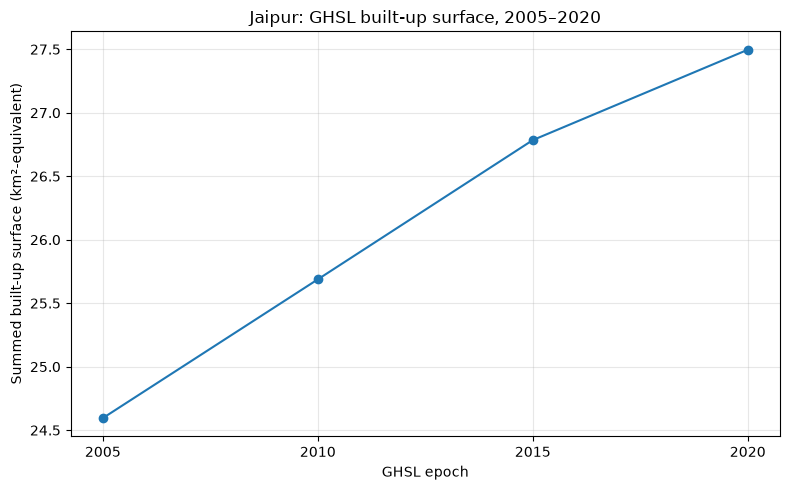

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(stats["year"], stats["built_surface_km2_equivalent"], marker="o")
plt.xticks(EPOCHS)
plt.xlabel("GHSL epoch")
plt.ylabel("Summed built-up surface (km²-equivalent)")
plt.title("Jaipur: GHSL built-up surface, 2005–2020")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Identify major growth zones
Use the positive-change layer to describe the spatial distribution. Visually inspect where the warm colours are clustered, then name directions or corridors only after checking the rendered map. Do not invent specific growth zones before looking at the output.

For an optional ranked grid-cell table, export/sample the expansion raster or use zonal statistics with a defensible set of zones (e.g. wards). The current boundary release provides ULB/ward options, but a ward-level analysis requires the appropriate ward dataset and a verified Jaipur ward subset.

## 12. Report-ready methodology, results and discussion
### Methodology
This study uses the Global Human Settlement Layer (GHSL) built-up surface product accessed in Google Earth Engine through `JRC/GHSL/P2023A/GHS_BUILT_S`. The `built_surface` band represents square metres of built-up surface per 100 m grid cell. The 2005, 2010, 2015 and 2020 epoch images were clipped to the **JAIPUR** Urban Local Body selected from the `SBM_ULBs` dataset in the Indian administrative-boundaries urban release.

The same boundary, band, nominal scale and visualization range were used for all epochs. No seasonal-window or cloud-quality filter was required because the assigned GHSL product is an epoch-based built-surface dataset rather than a cloud-prone monthly optical/Sentinel series. An interactive time slider and labelled GIF show the four available epochs. Net change was calculated as 2020 minus 2005, and positive expansion was isolated by setting negative differences to zero. Total mapped built-up surface was estimated by summing `built_surface` within the Jaipur boundary for each epoch.

### Results
- **2005:** 86.13 km²-equivalent of mapped built-up surface.
- **2010:** 100.32 km²-equivalent (**+16.47%** relative to 2005).
- **2015:** 114.44 km²-equivalent (**+32.87%** relative to 2005).
- **2020:** 121.50 km²-equivalent (**+41.06%** relative to 2005).
- **2005–2020 absolute increase:** 35.37 km²-equivalent.

### Discussion
The GHSL results show a clear overall increase in mapped built-up surface within the Jaipur ULB between 2005 and 2020. The summed built-up surface rose from approximately **86.13 km²-equivalent in 2005 to 121.50 km²-equivalent in 2020**, an increase of approximately **35.37 km²-equivalent, or 41.06%**. The intermediate epochs also show continued growth, reaching 100.32 km²-equivalent in 2010 and 114.44 km²-equivalent in 2015. Thus, the temporal pattern is an overall increase across all four available epochs rather than a single end-period jump.

The positive-expansion map identifies the locations where mapped built-up surface increased relative to the 2005 baseline. The strongest spatial clusters should be described from the rendered map itself. Directional claims such as northern, southern, eastern or western expansion should only be made when clearly supported by the map. The time slider and GIF provide a visual way to examine how the mapped built-up pattern evolves between the four five-year epochs.

**Interpretation caution:** 41.06% refers to the increase in the **summed GHSL built-up-surface measurement**, not a 41.06% increase in Jaipur's total administrative land area. The km²-equivalent is the summed built-up surface divided by one million.

### Limitations
1. **Temporal resolution:** GHSL provides five-year epochs in this analysis, so the result is not an annual time series and exact construction dates cannot be inferred.
2. **Spatial resolution:** the product uses a 100 m grid; small or fragmented developments may not be represented at building scale.
3. **Measurement meaning:** `built_surface` is built-up surface within grid cells, not a vector inventory of individual building footprints.
4. **Boundary dependence:** all statistics depend on the selected Jaipur ULB boundary; a district, ward, or different municipal boundary would produce different totals.
5. **Uncertainty:** observed differences can include dataset estimation/classification uncertainty as well as genuine land-development change.
6. **Change interpretation:** a positive 2020–2005 difference indicates increased mapped built-up surface, but the difference map alone does not establish the exact date, cause, or type of development.

### Data acknowledgement
Global Human Settlement Layer (GHSL), European Commission Joint Research Centre, GHS-BUILT-S R2023A. Jaipur ULB boundary: `SBM_ULBs` from `ramSeraph/indian_admin_boundaries`, urban release.
